(lecture10:homework)=
# Homework 10

+ Type your name and email in the "Student details" section below.
+ Develop the code and generate the figures you need to solve the problems using this notebook.
+ For the answers that require a mathematical proof or derivation you can either:
    
    - Type the answer using the built-in latex capabilities. In this case, simply export the notebook as a pdf and upload it on gradescope; or
    - You can print the notebook (after you are done with all the code), write your answers by hand, scan, turn your response to a single pdf, and upload on gradescope.

+ The total homework points are 100. Please note that the problems are not weighed equally.

```{note}
+ Please match all the pages corresponding to each of the questions when you submit on gradescope.
```

## Student details

+ **First Name: Hunter**
+ **Last Name: Frommelt**
+ **Email: hfrommel@purdue.edu**

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set(rc={"figure.dpi":100, 'savefig.dpi':300})
sns.set_context('notebook')
sns.set_style("ticks")
from IPython.display import set_matplotlib_formats
set_matplotlib_formats('retina', 'svg')
import numpy as np
import scipy.stats as st

/tmp/ipykernel_3445/122018214.py:8: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  set_matplotlib_formats('retina', 'svg')


(lecture10:homework:problem1)=
## Problem 1 - An alternative way to construct the generalized uniform distribution $U([a,b])$

Let $Z$ be a standard uniform random variable:

$$
Z\sim U([0,1]).
$$

Define the random variable:

$$
X = a + (b-a) Z.
$$

+ Show that:

$$
X\sim U([a,b]).
$$

Hint: Prove that the CDF of $X$ is $F_X(x) = p(X\le x) = \frac{x-a}{b-a}$. This is one line.

**Answer:**

$Z = F_Z(x) = p(Z\le x) = x$

$X = a + (b-a) * Z$

$X = p((a + (b-a)) * Z \le x)$

$X = p((b-a) * Z \le x - a)$

$X = p(Z \le \frac{x-a}{b-a})$

$X = p(Z \le x) = \frac{x-a}{b-a}$


$X = F_X(x) = p(X\le x) = \frac{x-a}{b-a}$

+ The function `numpy.random.rand` gives you uniform random samples in $[0, 1]$.
Take 1,000 such samples and transform them to uniform samples in $[-1, 5]$.
Hint: Fill in the missing code below.

In [3]:
a = -1
b = 5
z = np.random.rand(1000)
x =  z * (b-a) + a

Test if you are getting the right answer by doing the histogram of your samples (it should be almost flat between -1 and 5):

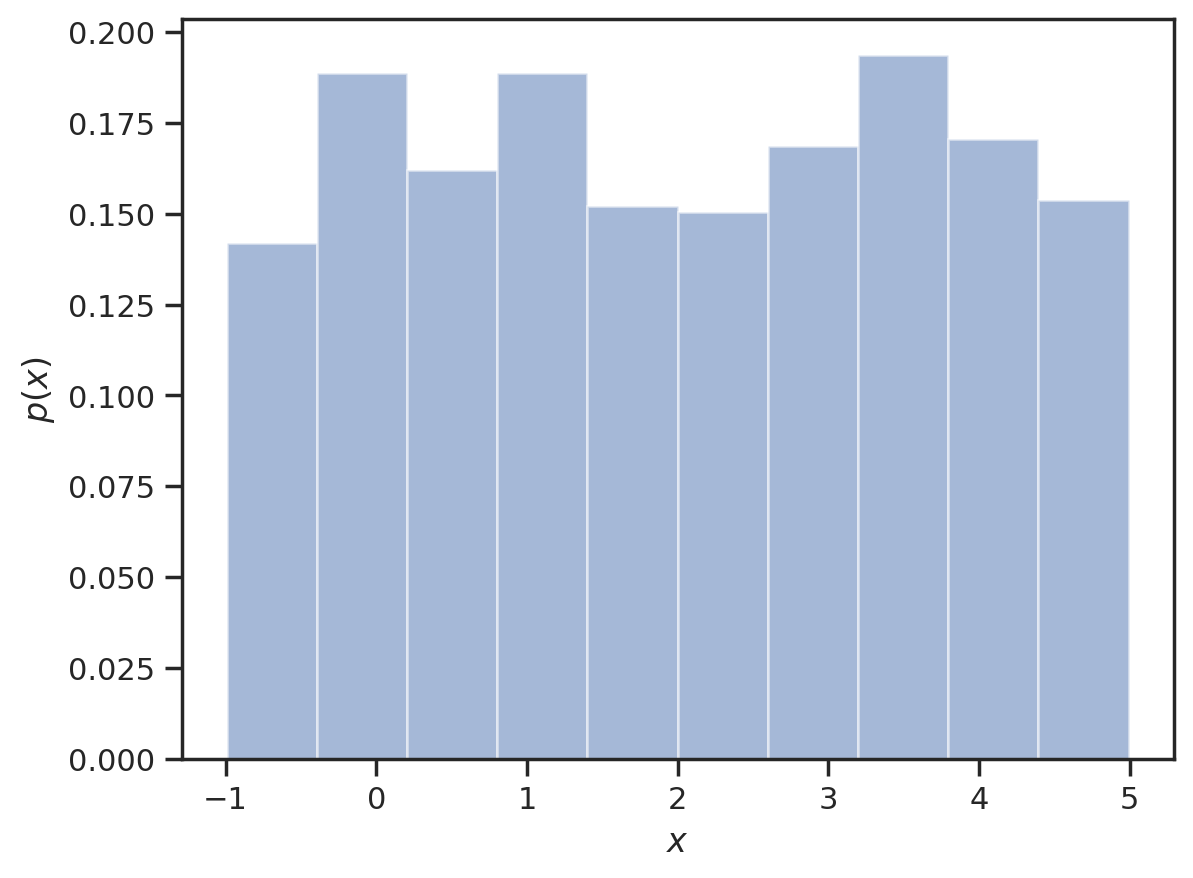

In [4]:
fig, ax = plt.subplots()
ax.hist(x, density=True, alpha=0.5)
ax.set_xlabel('$x$')
ax.set_ylabel('$p(x)$');

(lecture10:homework:problem2)=
# Problem 2 - The Exponential distribution

The Exponential distribution models the probability distribution of the time between events which occur [continuously and independently at a constant rate](https://en.wikipedia.org/wiki/Exponential_distribution).
Examples of such a situation are:
+ The time between phone calls in a help center.
+ The time between the arrival of cars at a toll station.
+ The time between the arrival of customers.
+ The time between two earthquakes.
+ The time between two micrometeoroid impacts on an Moon research base.
+ The time between faults in a mechanical system. However, this is a gross approximation because the rate of faults in a mechanical system increases with time, it is not constant.

We write:

$$
T \sim \text{Exp}(\lambda),
$$

and we read:

> $T$ follows an Exponential distribution with rate parameter $\lambda$.

The rate parameter $\lambda$ is positive and has units of inverse time.
You can think of $\lambda$ as the number of events per unit of time.

The CDF of the Exponential is:

$$
F(t) = \begin{cases}
0,& t < 0,\\
1 - e^{-\lambda t},& t \ge 0.
\end{cases}
$$

+ Prove mathematically that the PDF of the random variable $T$ is:

$$
p(t) = \lambda e^{-\lambda t}.
$$

Hint: Use one of the properties of the PDF.

**Answer:**

$p(t) = \frac{d}{dt}F(t)$

$p(t) = \frac{d}{dt}(1 - e^{-\lambda t})$

$p(t) = \lambda e^{-\lambda t}$

+ [Micrometeoroids](https://en.wikipedia.org/wiki/Micrometeoroid) make space exploration very challenging.
Even though the mass of these projectiles is very small (less than 1 gram), they move with a very high-velocity
(of the order of 10 km per second) and thus they are will be gradually degrading the protective layers of deep space habitats.
For a Moon base with an area of 1000 squared meters, the rate of micrometeoroid impacts is about:

$$
\lambda = 3\times 10^{-6}\;\text{s}^{-1}.
$$

Read the [scipy.stats.expon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.expon.html) documentation and make an Exponential random variable $T$ with this rate:

In [5]:
# You cannot use lambda because it is a reserved word.
# Call the rate lam instead:
lam = 3e-6 # in inverse seconds
T = st.expon(scale = 1 / lam)

+ Take 1000 samples from the random variable you just constructed and draw their histogram.


In [6]:
samples = T.rvs(1000)

+ Plot the CDF of $T$:

Text(0, 0.5, 'Frequency')

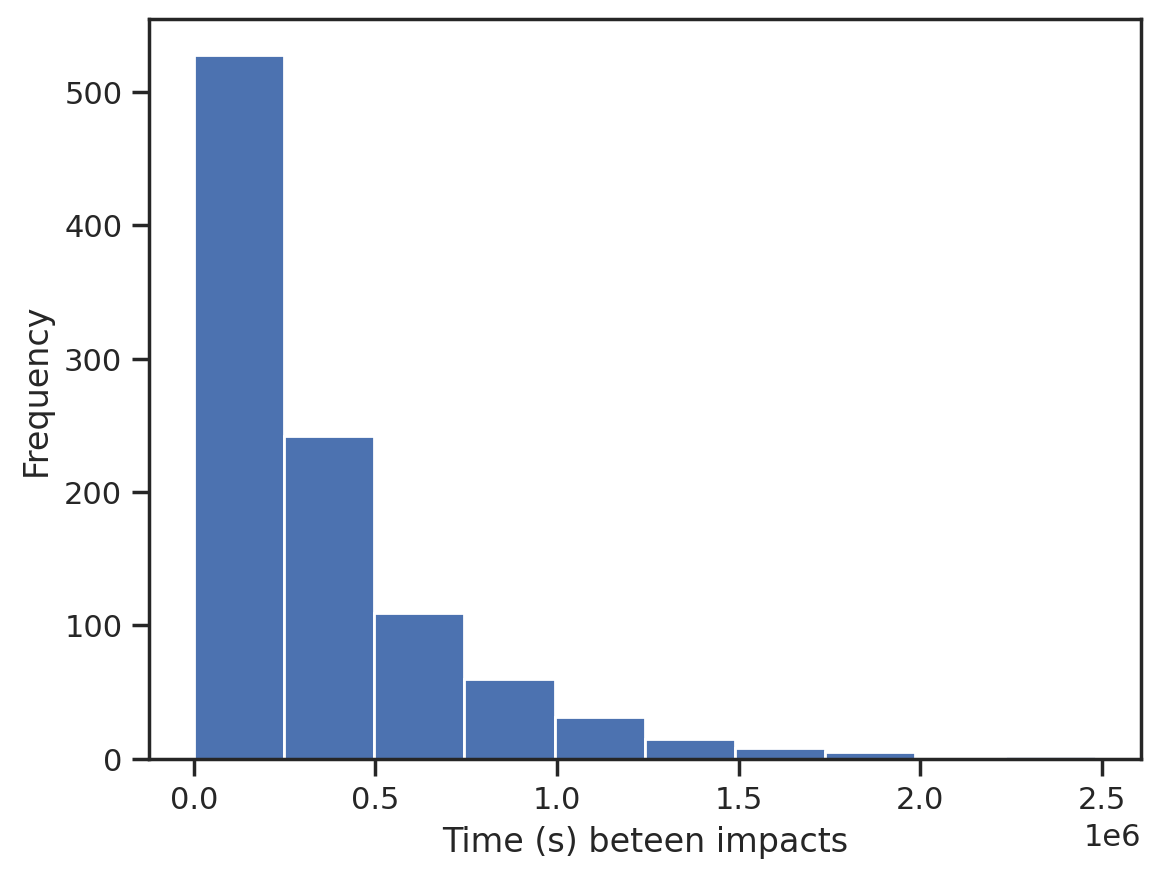

In [7]:
plt.hist(samples)
plt.xlabel("Time (s) beteen impacts")
plt.ylabel("Frequency")

+ Find the probability that we have a micrometeoroid impact within a day.
Hint: Remember that the units of $T$ are seconds.

Text(0, 0.5, 'Frequency')

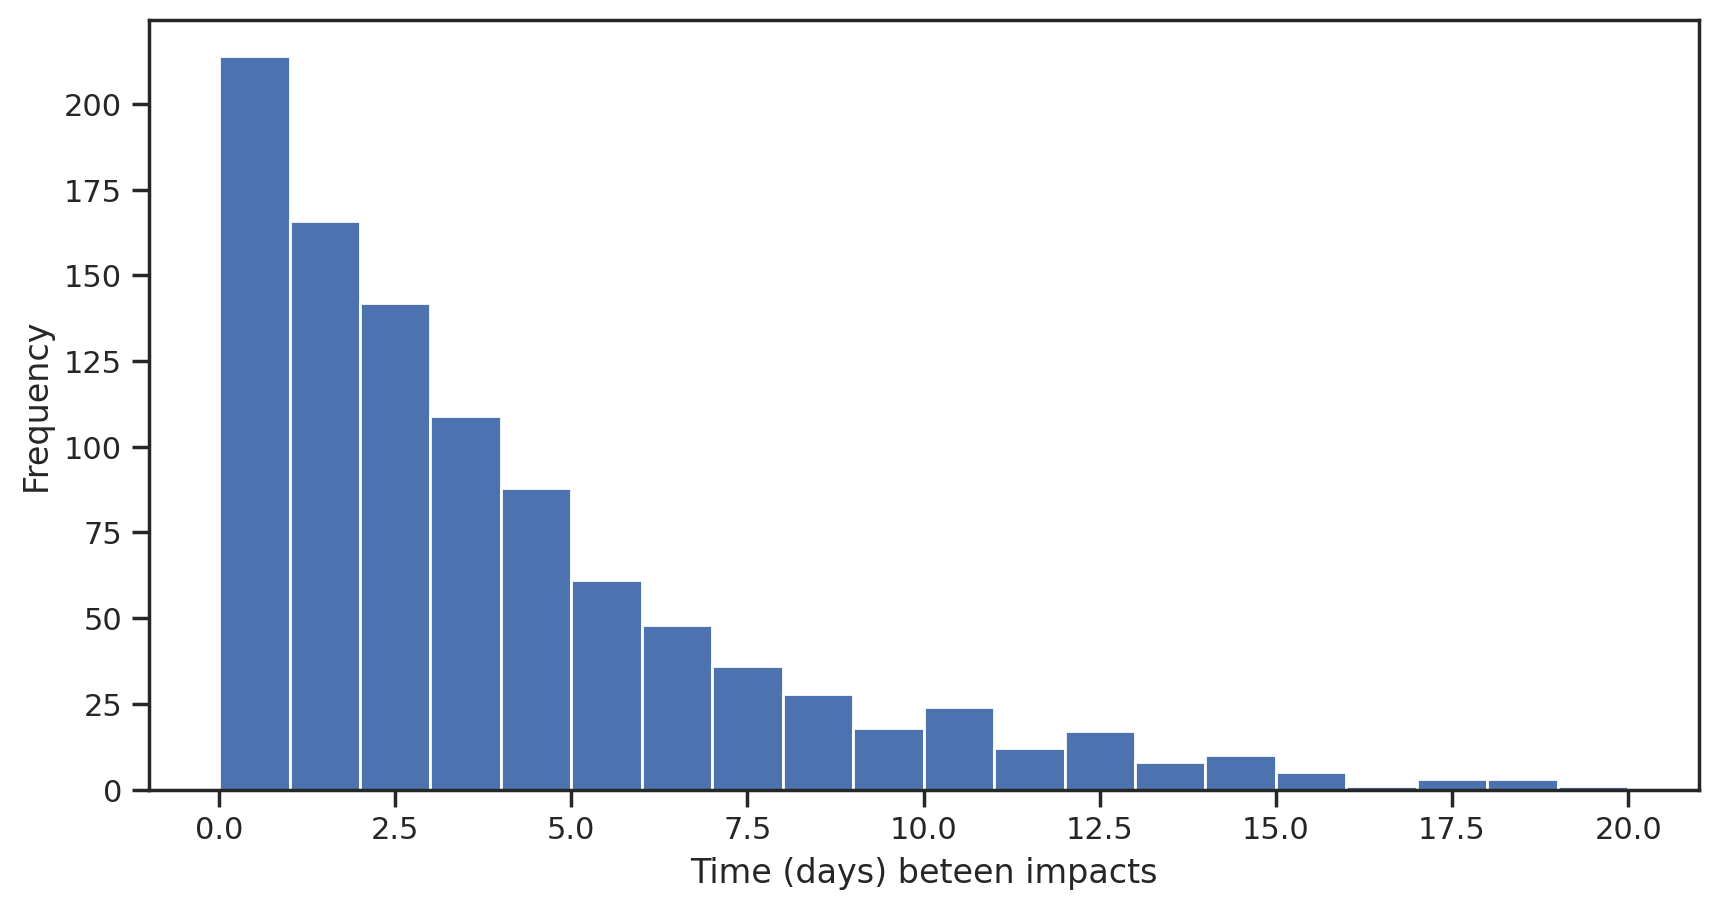

In [8]:
samples = T.rvs(1000) / 86400
plt.figure(figsize=(10, 5))
plt.hist(samples, range = (0, 20), bins = 20)
plt.xlabel("Time (days) beteen impacts")
plt.ylabel("Frequency")

+ Plot the PDF of T.

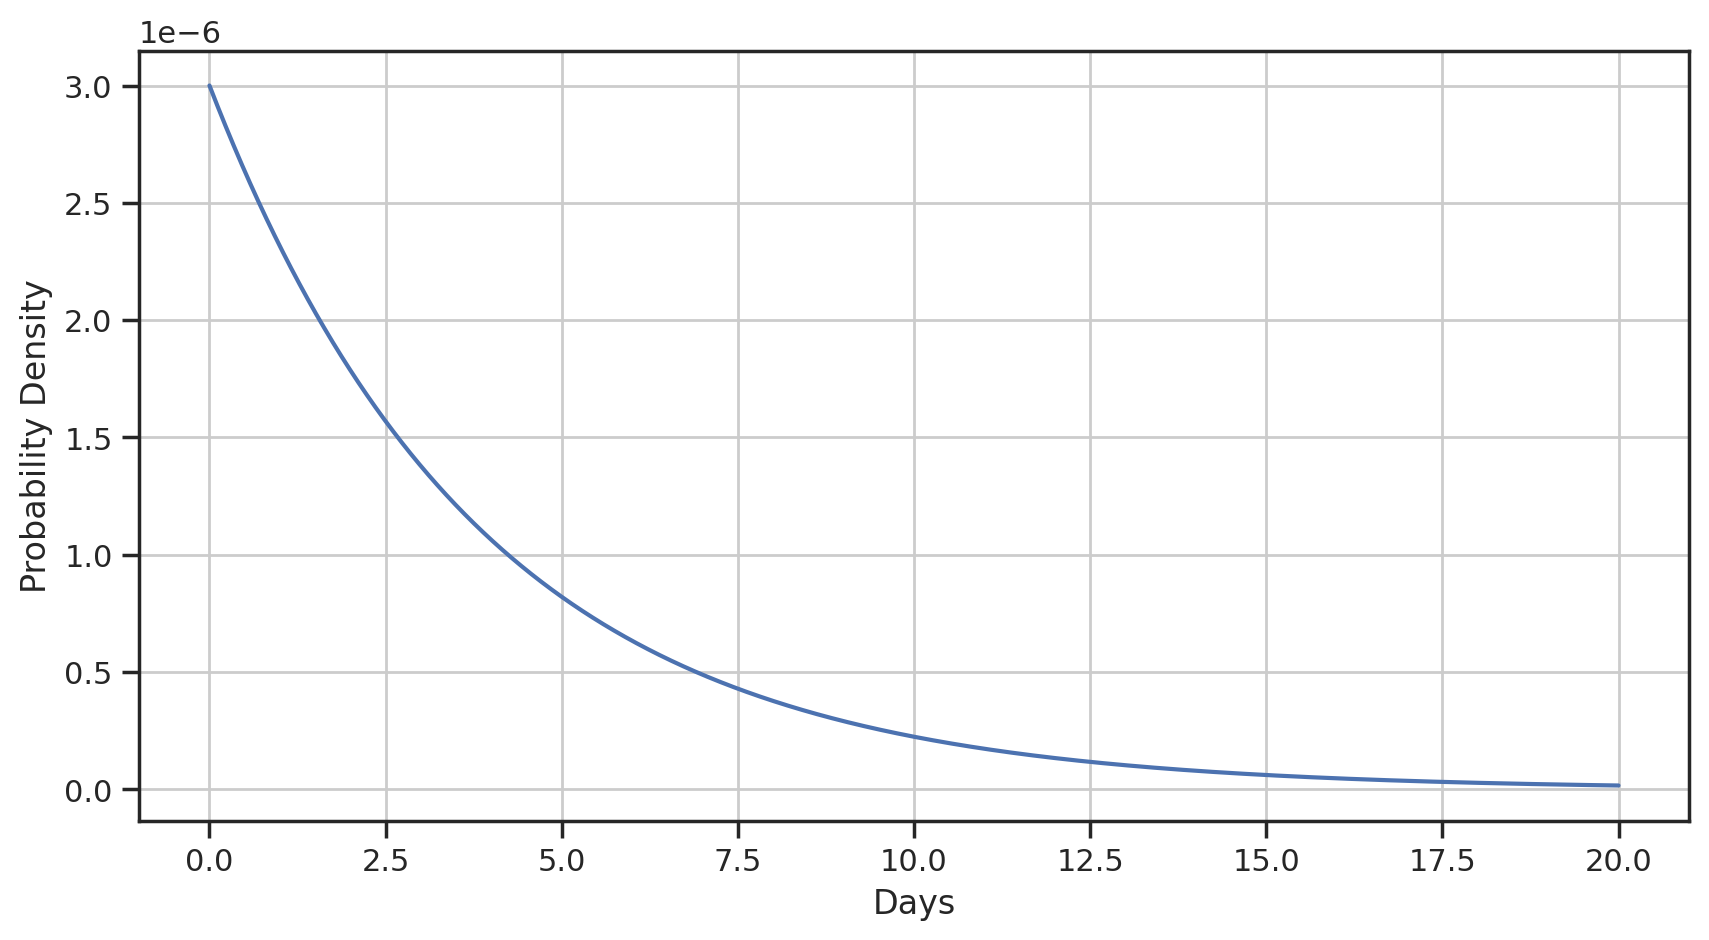

In [25]:
# p(t) = \lambda e^{-\lambda t}.
import math

sec_per_day = 86400
day_count = 20
seconds = np.linspace(0, sec_per_day * day_count, sec_per_day)
probability = lam * np.exp(-lam * seconds)
days = seconds / sec_per_day
plt.figure(figsize=(10, 5))
plt.plot(days, probability);
plt.xlabel("Days");
plt.ylabel("Probability Density");
plt.grid(True)

Run the following code to convert the notebook to a pdf. Verify that the file path to the notebook is correct.

In [26]:
def colab2pdf():
  # @title Download Notebook in PDF Format{display-mode:'form'}
  !apt-get install -yqq --no-install-recommends librsvg2-bin>/dev/null;
  import contextlib,datetime,google,io,IPython,ipywidgets,json,locale,nbformat,os,pathlib,requests,urllib,warnings,werkzeug,yaml,re;locale.setlocale(locale.LC_ALL,'en_US.UTF-8');warnings.filterwarnings('ignore',category=nbformat.validator.MissingIDFieldWarning);
  %matplotlib inline
  def convert(b):
    try:
      s.value='🔄 Converting';b.disabled=True
      n=pathlib.Path(werkzeug.utils.secure_filename(urllib.parse.unquote(requests.get(f'http://{os.environ["COLAB_JUPYTER_IP"]}:{os.environ["KMP_TARGET_PORT"]}/api/sessions').json()[0]['name'])))
      p=pathlib.Path('/content/pdfs')/f'{datetime.datetime.utcnow().strftime("%Y%m%d_%H%M%S")}_{n.stem}';p.mkdir(parents=True,exist_ok=True);nb=nbformat.reads(json.dumps(google.colab._message.blocking_request('get_ipynb',timeout_sec=600)['ipynb']),as_version=4)
      u=[u for c in nb.cells if c.get('cell_type')=='markdown' for u in re.findall(r'!\[.*?\]\((https?://.*?)\)',c['source']) if requests.head(u,timeout=5).status_code!=200]
      if u:raise Exception(f"Bad Image URLs: {','.join(u)}")
      nb.cells=[cell for cell in nb.cells if '--Colab2PDF' not in cell.source]
      nb=nbformat.v4.new_notebook(cells=nb.cells or [nbformat.v4.new_code_cell('#')]);nbformat.validator.normalize(nb)
      nbformat.write(nb,(p/f'{n.stem}.ipynb').open('w',encoding='utf-8'))
      with (p/'config.yml').open('w', encoding='utf-8') as f: yaml.dump({'include-in-header':[{'text':r'\usepackage{fvextra}\DefineVerbatimEnvironment{Highlighting}{Verbatim}{breaksymbolleft={},showspaces=false,showtabs=false,breaklines,breakanywhere,commandchars=\\\{\}}'}],'include-before-body':[{'text':r'\DefineVerbatimEnvironment{verbatim}{Verbatim}{breaksymbolleft={},showspaces=false,showtabs=false,breaklines}'}]},f)
      !quarto render {p}/{n.stem}.ipynb --metadata-file={p}/config.yml --to pdf -M latex-auto-install -M margin-top=1in -M margin-bottom=1in -M margin-left=1in -M margin-right=1in --quiet
      google.colab.files.download(str(p/f'{n.stem}.pdf'));s.value=f'✅ Downloaded: {n.stem}.pdf'
    except Exception as e:s.value=f'❌ {str(e)}'
    finally:b.disabled=False
  if not pathlib.Path('/usr/local/bin/quarto').exists():
    !wget -q 'https://quarto.org/download/latest/quarto-linux-amd64.deb' && dpkg -i quarto-linux-amd64.deb>/dev/null && quarto install tinytex --update-path --quiet && rm quarto-linux-amd64.deb
  b=ipywidgets.widgets.Button(description='⬇️ Download');s=ipywidgets.widgets.Label();b.on_click(lambda b:convert(b));IPython.display.display(ipywidgets.widgets.HBox([b,s]))
colab2pdf() # | Colab2PDF v1.6 | https://github.com/drengskapur/colab2pdf | GPL-3.0-or-later |

/tmp/ipykernel_3445/41980980.py:10: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  p=pathlib.Path('/content/pdfs')/f'{datetime.datetime.utcnow().strftime("%Y%m%d_%H%M%S")}_{n.stem}';p.mkdir(parents=True,exist_ok=True);nb=nbformat.reads(json.dumps(google.colab._message.blocking_request('get_ipynb',timeout_sec=600)['ipynb']),as_version=4)
